# Olist Sentinel: Late-Delivery Risk Model

**Goal:** predict, at the moment an order is placed, whether it will arrive after its promised delivery date.

**How this notebook is organised**
1. Load the data
2. Create the target (`is_late`)
3. Build one row per order
4. Engineer features (distance, timing, seller history)
5. Check why `month` is not used
6. Evaluate with a rolling time-based backtest (XGBoost vs logistic regression)
7. Train the final model and explain it with SHAP
8. Print the numbers for your resume

**Rules followed throughout:** only information known at purchase time is used as a feature, and every test set is later in time than its training set.

## 0. Imports and settings

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

DATA_DIR = "../data"      # the notebook lives in ipynb_files/, the CSVs in data/
RANDOM_STATE = 0

## 1. Load the data

Only the six tables this model needs are loaded. Reviews and payments are used later, for the review and KPI analysis.

In [2]:
FILES = {
    "customers":   "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "orders":      "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
}
tables = {name: pd.read_csv(os.path.join(DATA_DIR, f)) for name, f in FILES.items()}

customers   = tables["customers"]
geolocation = tables["geolocation"]
orders      = tables["orders"]
order_items = tables["order_items"]
products    = tables["products"]
sellers     = tables["sellers"]

{name: df.shape for name, df in tables.items()}

{'customers': (99441, 5),
 'geolocation': (1000163, 5),
 'orders': (99441, 8),
 'order_items': (112650, 7),
 'products': (32951, 9),
 'sellers': (3095, 4)}

## 2. Create the target: was the order late?

- Dates are stored as text, so convert them to real datetimes first.
- Keep only **delivered** orders. Canceled or in-transit orders have no delivery date, so there is no answer to learn from.
- `is_late = 1` if the order arrived after the estimated date.
- `delay_days` is for analysis only (for example the review-score study). **Never use it as a model feature**, because it reveals the answer.

In [3]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

delivered = orders[orders.order_status == "delivered"].dropna(
    subset=["order_delivered_customer_date"]).copy()

delivered["is_late"] = (delivered.order_delivered_customer_date >
                        delivered.order_estimated_delivery_date).astype(int)
delivered["delay_days"] = (delivered.order_delivered_customer_date -
                           delivered.order_estimated_delivery_date).dt.days   # analysis only

print(f"Delivered orders: {len(delivered):,}   late rate: {delivered.is_late.mean():.1%}")

Delivered orders: 96,470   late rate: 8.1%


## 3. Build one row per order

`order_items` has one row per item, so an order with 3 items appears 3 times. The model predicts per order, so items are summed up into a single row. Then customer, seller and product details are joined on.

*Simplification:* for orders with several items, the first seller and product are used.

In [4]:
items = order_items.groupby("order_id").agg(
    freight=("freight_value", "sum"),
    price=("price", "sum"),
    n_items=("order_item_id", "count"),
    seller_id=("seller_id", "first"),
    product_id=("product_id", "first"),
).reset_index()

df = (delivered
      .merge(items, on="order_id")
      .merge(customers[["customer_id", "customer_zip_code_prefix", "customer_state"]], on="customer_id")
      .merge(sellers[["seller_id", "seller_zip_code_prefix", "seller_state"]], on="seller_id")
      .merge(products[["product_id", "product_weight_g", "product_length_cm",
                       "product_height_cm", "product_width_cm"]], on="product_id"))

print(f"Modelling table: {df.shape[0]:,} rows, one per order")

Modelling table: 96,470 rows, one per order


## 4. Feature engineering

### 4a. Distance between seller and customer
Customers and sellers only have a zip prefix. The geolocation table has many points per prefix, so take the **average point per prefix**, attach it to each side, then compute the straight-line distance with the haversine formula.

In [5]:
geo = (geolocation.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
       .mean().reset_index())

def add_coords(data, zip_col, tag):
    g = geo.rename(columns={"geolocation_zip_code_prefix": zip_col,
                            "geolocation_lat": f"{tag}_lat",
                            "geolocation_lng": f"{tag}_lng"})
    return data.merge(g, on=zip_col, how="left")

def haversine(lat1, lon1, lat2, lon2):
    """Distance in km between two points on Earth."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

df = add_coords(df, "customer_zip_code_prefix", "cust")
df = add_coords(df, "seller_zip_code_prefix", "sell")
df["distance_km"] = haversine(df.cust_lat, df.cust_lng, df.sell_lat, df.sell_lng)

### 4b. Timing and simple features

| Feature | Why it helps |
|---|---|
| `hour`, `dow` | Weekend and late-night orders may be handled more slowly |
| `same_state` | Shipping inside a state is usually faster |
| `volume_cm3` | Bulky items are harder to ship than the three separate sizes suggest |
| `promised_days` | The delivery window promised at purchase. Known at purchase time, so it is not leakage |

In [6]:
df["hour"] = df.order_purchase_timestamp.dt.hour
df["dow"] = df.order_purchase_timestamp.dt.dayofweek
df["same_state"] = (df.customer_state == df.seller_state).astype(int)
df["volume_cm3"] = df.product_length_cm * df.product_height_cm * df.product_width_cm
df["promised_days"] = (df.order_estimated_delivery_date - df.order_purchase_timestamp).dt.days

### 4c. Seller history and current platform conditions (leakage-safe)

Two features describe how things were going **just before** the order was placed:

- `seller_late_rate` and `seller_n_orders`: the seller's record over orders already delivered
- `platform_late_recent`: the late rate over the last 1,000 delivered orders on the whole platform

To avoid leakage, each order only sees orders **delivered before its own purchase time**. This is done with `merge_asof`, which looks backwards in time. `allow_exact_matches=False` makes sure the order cannot see itself.

In [7]:
# Running history, ordered by delivery time
hist = (df[["seller_id", "order_delivered_customer_date", "is_late"]]
        .sort_values("order_delivered_customer_date").copy())
hist = hist.rename(columns={"order_delivered_customer_date": "hist_time"})

grp = hist.groupby("seller_id")
hist["seller_n_orders"] = grp.cumcount() + 1
hist["seller_late_rate"] = grp.is_late.cumsum() / hist["seller_n_orders"]
hist["platform_late_recent"] = hist.is_late.rolling(1000, min_periods=100).mean()

df = df.sort_values("order_purchase_timestamp")

# Seller history as of the purchase time
df = pd.merge_asof(
    df, hist[["seller_id", "hist_time", "seller_late_rate", "seller_n_orders"]],
    left_on="order_purchase_timestamp", right_on="hist_time",
    by="seller_id", direction="backward", allow_exact_matches=False,
).drop(columns="hist_time")

# Platform-wide recent late rate as of the purchase time
df = pd.merge_asof(
    df.sort_values("order_purchase_timestamp"),
    hist[["hist_time", "platform_late_recent"]].dropna().sort_values("hist_time"),
    left_on="order_purchase_timestamp", right_on="hist_time",
    direction="backward", allow_exact_matches=False,
).drop(columns="hist_time")

df = df.reset_index(drop=True)
df[["seller_late_rate", "seller_n_orders", "platform_late_recent"]].describe().round(3)

,seller_late_rate,seller_n_orders,platform_late_recent
count,91189.000,91189.000,96204.000
mean,0.054,178.860,0.076
std,0.074,287.983,0.060
min,0.000,1.000,0.000
25%,0.000,16.000,0.033
50%,0.038,59.000,0.055
75%,0.074,194.000,0.106
max,1.000,1788.000,0.239


## 5. Why `month` is not a feature

The late rate swings widely from month to month, driven by one-off events (Black Friday, Carnival, delivery disruptions). The data covers under two years, so every month appears only once or twice. A model given `month` just memorises *"November 2017 was bad"* and then fails on new months. We leave `month` out and let `platform_late_recent` capture the current conditions instead.

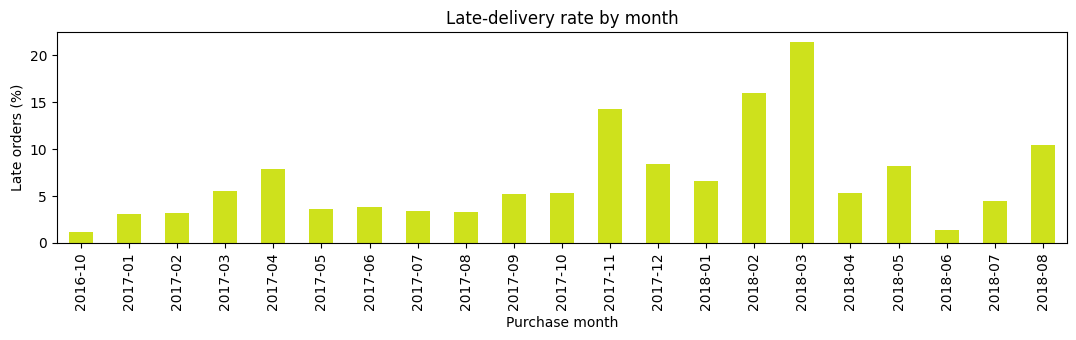

In [14]:
monthly = df.groupby(df.order_purchase_timestamp.dt.to_period("M")).is_late.agg(["mean", "size"])
monthly = monthly[monthly["size"] >= 100]          # ignore the tiny 2016 months

ax = (monthly["mean"] * 100).plot(kind="bar", figsize=(11, 3.5), color="#CEE11C")
ax.set_ylabel("Late orders (%)")
ax.set_xlabel("Purchase month")
ax.set_title("Late-delivery rate by month")
plt.tight_layout()
plt.show()

## 6. Evaluation: rolling time-based backtest

**Why not one train/test split?** One 3-month test window can be unusually calm or unusually bad, so a single number is not trustworthy. Here the models are trained on the past and tested on five later 2-month windows, then the results are averaged.

**Metrics** (accuracy is useless when only about 8% of orders are late):
- **Lift** = PR-AUC divided by the late rate. 1.0 is random, higher is better.
- **Top-10% capture** = the share of all late orders found among the 10% of orders the model rates riskiest. Random flagging would capture 10%.

**Models:** logistic regression is the simple baseline, and XGBoost is the main model. Both are kept deliberately simple, so they do not memorise the training period.

In [9]:
FEATURES = ["hour", "dow", "freight", "price", "n_items", "product_weight_g", "volume_cm3",
            "distance_km", "same_state", "promised_days",
            "seller_late_rate", "seller_n_orders", "platform_late_recent"]

def make_models():
    logistic = make_pipeline(StandardScaler(),
                             LogisticRegression(max_iter=1000, class_weight="balanced"))
    xgb = XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.05,
                        min_child_weight=50, subsample=0.8, colsample_bytree=0.8,
                        reg_lambda=5, random_state=RANDOM_STATE)
    return logistic, xgb

def top_decile(y_true, scores, frac=0.10):
    """Share of all late orders found in the riskiest `frac` of orders, and precision there."""
    n = int(len(y_true) * frac)
    top = np.argsort(-np.asarray(scores))[:n]
    hits = np.asarray(y_true)[top]
    return hits.sum() / np.sum(y_true), hits.mean()

def fit_and_score(train_df, test_df):
    """Train both models on train_df, return their risk scores for test_df."""
    Xtr, ytr, Xte = train_df[FEATURES], train_df.is_late, test_df[FEATURES]
    logistic, xgb = make_models()
    median = Xtr.median()                       # logistic regression cannot handle missing values
    logistic.fit(Xtr.fillna(median), ytr)
    xgb.fit(Xtr, ytr)                           # XGBoost handles missing values itself
    return (logistic.predict_proba(Xte.fillna(median))[:, 1],
            xgb.predict_proba(Xte)[:, 1], xgb)

In [10]:
CUTOFFS = ["2017-10-01", "2017-12-01", "2018-02-01", "2018-04-01", "2018-06-01"]

rows = []
for c in CUTOFFS:
    c = pd.Timestamp(c)
    train_df = df[df.order_purchase_timestamp < c]
    test_df = df[(df.order_purchase_timestamp >= c) &
                 (df.order_purchase_timestamp < c + pd.DateOffset(months=2))]
    p_lr, p_xgb, _ = fit_and_score(train_df, test_df)
    y, rate = test_df.is_late, test_df.is_late.mean()
    rows.append({
        "test_window_from": c.date(),
        "late_rate": rate,
        "lr_lift": average_precision_score(y, p_lr) / rate,
        "xgb_lift": average_precision_score(y, p_xgb) / rate,
        "lr_top10_capture": top_decile(y, p_lr)[0],
        "xgb_top10_capture": top_decile(y, p_xgb)[0],
    })

backtest = pd.DataFrame(rows)
display(backtest.round(2))
print("Average across windows")
display(backtest.drop(columns="test_window_from").mean().round(2).to_frame("average").T)

,test_window_from,late_rate,lr_lift,xgb_lift,lr_top10_capture,xgb_top10_capture
0,2017-10-01,0.11,1.37,1.26,0.17,0.15
1,2017-12-01,0.07,1.34,1.61,0.16,0.18
2,2018-02-01,0.19,1.68,1.56,0.20,0.18
3,2018-04-01,0.07,2.43,2.09,0.29,0.26
4,2018-06-01,0.03,3.18,3.50,0.31,0.28


Average across windows


,late_rate,lr_lift,xgb_lift,lr_top10_capture,xgb_top10_capture
average,0.09,2.0,2.0,0.23,0.21


**How to read it:** lift above 1 means the model ranks late orders better than chance, and top-10% capture above 0.10 means the same thing in business terms. Expect lift to be highest in calm periods and lowest during crises, because shocks are hard to foresee from order details.

## 7. Final model on a holdout set and SHAP explanation

The model is trained on the earliest 80% of orders and tested on the latest 20%, which is a clean "future" the model has never seen. SHAP then shows which features push an order toward *late* or *on time*.

In [11]:
cut = int(len(df) * 0.8)
train_df, test_df = df.iloc[:cut], df.iloc[cut:]
print(f"Train: {train_df.order_purchase_timestamp.min().date()} to {train_df.order_purchase_timestamp.max().date()}")
print(f"Test : {test_df.order_purchase_timestamp.min().date()} to {test_df.order_purchase_timestamp.max().date()}")

p_lr, p_xgb, final_xgb = fit_and_score(train_df, test_df)
y, rate = test_df.is_late, test_df.is_late.mean()

holdout = pd.DataFrame({
    "late_rate": [rate, rate],
    "pr_auc_lift": [average_precision_score(y, p_lr) / rate, average_precision_score(y, p_xgb) / rate],
    "top10_capture": [top_decile(y, p_lr)[0], top_decile(y, p_xgb)[0]],
    "top10_precision": [top_decile(y, p_lr)[1], top_decile(y, p_xgb)[1]],
}, index=["Logistic regression", "XGBoost"])
holdout.round(3)

Train: 2016-09-15 to 2018-05-26
Test : 2018-05-26 to 2018-08-29


,late_rate,pr_auc_lift,top10_capture,top10_precision
Logistic regression,0.053,1.760,0.207,0.109
XGBoost,0.053,1.307,0.151,0.080


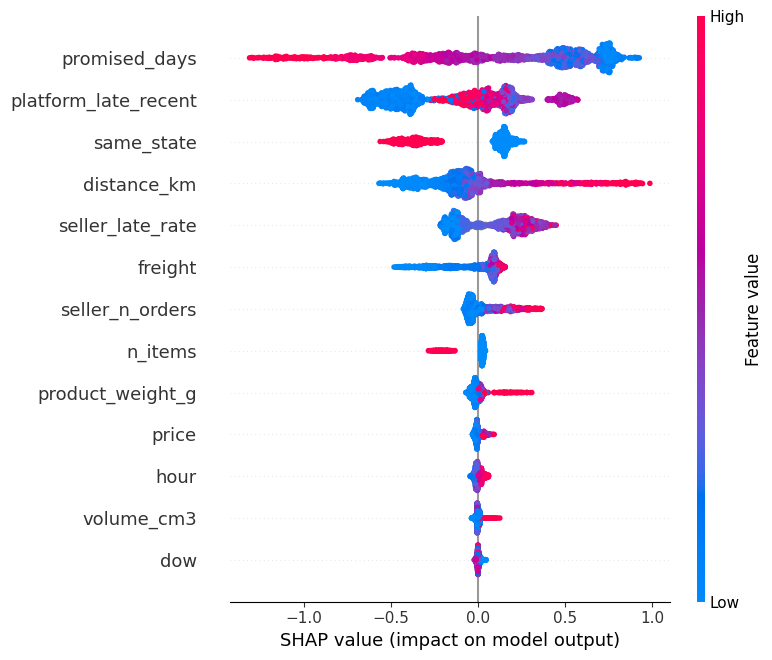

In [12]:
sample = test_df[FEATURES].sample(min(2000, len(test_df)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(final_xgb)
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample)

**Reading the SHAP plot:** features are ranked by overall importance. Each dot is one order. A dot to the right pushed that prediction toward *late*, and the colour shows the feature value (red = high). For example, red dots on the right for `distance_km` mean long distances raise the late risk.

## 8. Numbers for your resume

These lines are filled from your own results. Use these numbers, and only these.

In [13]:
avg = backtest.drop(columns="test_window_from").mean()

# Use whichever model did better on average across the backtest windows
if avg.xgb_lift >= avg.lr_lift:
    best, lift, capture = "XGBoost", avg.xgb_lift, avg.xgb_top10_capture
else:
    best, lift, capture = "Logistic regression", avg.lr_lift, avg.lr_top10_capture

print(f"Backtest windows        : {len(backtest)} (rolling, time-based)")
print(f"Average PR-AUC lift     : XGBoost {avg.xgb_lift:.2f}x | Logistic regression {avg.lr_lift:.2f}x  (random = 1.00x)")
print(f"Top-10% riskiest orders : XGBoost {avg.xgb_top10_capture:.0%} | Logistic regression {avg.lr_top10_capture:.0%} of late deliveries (random = 10%)")
print(f"Better model on average : {best}")
print()

if lift < 1.3 or capture < 0.15:
    print("WARNING: the signal is weak (lift below 1.3x or top-10% capture below 15%).")
    print("Do not claim predictive performance on your resume. Report the analysis findings instead.")
else:
    print("Resume bullet draft:")
    print(f"Built a leakage-safe late-delivery risk model ({best}; seller history, shipping distance, promised delivery window) "
          f"validated with a {len(backtest)}-window rolling time-based backtest; flagging the riskiest 10% of orders captured "
          f"{capture:.0%} of late deliveries (about {capture/0.10:.1f}x random), and SHAP identified the top drivers.")

Backtest windows        : 5 (rolling, time-based)
Average PR-AUC lift     : XGBoost 2.00x | Logistic regression 2.00x  (random = 1.00x)
Top-10% riskiest orders : XGBoost 21% | Logistic regression 23% of late deliveries (random = 10%)
Better model on average : XGBoost

Resume bullet draft:
Built a leakage-safe late-delivery risk model (XGBoost; seller history, shipping distance, promised delivery window) validated with a 5-window rolling time-based backtest; flagging the riskiest 10% of orders captured 21% of late deliveries (about 2.1x random), and SHAP identified the top drivers.
